# Uncertainty Estimation

**Special thanks to Dr. Peyman Sheikhzadeh at the Tehran University Of Medical Science for providing this anonymized data**

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-PSMA-GEDisc")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-PSMA-GEDisc")

SPECT/Lu177-PSMA-GEDisc: already downloaded


In [2]:
import os
from pytomography import io
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.algorithms import OSEM, PGAAMultiBedSPECT
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.likelihoods import PoissonLogLikelihood
import matplotlib.pyplot as plt
import torch
from rt_utils import RTStructBuilder
from pytomography.callbacks import DataStorageCallback

In [3]:
save_path = DATA / 'SPECT'

The following code cell loads projection data and a corresponding CT file and creates a reconstruction algorithm; if you are unfamiliar with the code below or require more explanation, see that "DICOM Data Introduction" tutorial.
* **The only difference is that we now get a variance estimate for the scatter (`return_scatter_variance_estimate=True`), and then input that to the likelihood (`additive_term_variance_estimate`)**
* The collimator corresponding to this data is General Electric's medium energy general purpose collimator.

In [4]:
file_NM = os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'bed2_projections.dcm')
path_CT = os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'CT')
files_CT = [os.path.join(path_CT, file) for file in os.listdir(path_CT)]
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
photopeak = projections[1]
scatter, scatter_variance_estimate = io.SPECT.energy_window_scatter(projections, proj_meta, peak=1, lower=3, upper=2,
                                                                    return_scatter_variance_estimate=True)
# Build system matrix
photon_energy = proj_meta.energy_windows[1].photon_energy  # the 208 keV window
attenuation_map = io.attenuation_map(files_CT, object_meta, energy=photon_energy)
psf_meta = io.SPECT.collimator_psf('GI-MEGP', photon_energy)
att_transform = SPECTAttenuationTransform(attenuation_map)
psf_transform = SPECTPSFTransform(psf_meta)
system_matrix = SPECTSystemMatrix(
    obj2obj_transforms = [att_transform,psf_transform],
    proj2proj_transforms = [],
    object_meta = object_meta,
    proj_meta = proj_meta)
# Likelihood
likelihood = PoissonLogLikelihood(system_matrix, photopeak, additive_term=scatter, additive_term_variance_estimate=scatter_variance_estimate)
# Reconstruction algorithm
recon_algorithm = OSEM(likelihood)

Up to this point, we've created the reconstruction algorithm but we haven't performed reconstruction yet. If we plan on computing uncertainty in various VOIs, we are required to use the `DataStorageCallback` callback in the image reconstruction algorithm. This callback stores a copy of the reconstructed image at each iteration and subiteration: all this data is required when computing uncertainties later. It can be created as follows:

In [5]:
data_storage_callback = DataStorageCallback(likelihood, torch.clone(recon_algorithm.object_prediction))

Then we reconstruct using this callback, after printing the memory the reconstruction will need (`estimate_memory`):

In [6]:
print(recon_algorithm.estimate_memory(n_subsets=8))
recon_OSEM = recon_algorithm(n_iters = 4, n_subsets = 8, callback=data_storage_callback)

OSEM (SPECTSystemMatrix): 8 subsets
Peak ~ 4.3 GB RAM, 1.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.2 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.05 GPU, what the object transforms keep 0.01 GPU, projections (the data) 0.00 GPU, additive term 0.00 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.2 GB RAM, 0.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 0.1 RAM)
To use less: 4 subsets ~ 4.3 GB RAM, 1.1 GB GPU
(plus whate

Here's a coronal maximum intensity projection of the reconstruction

In [7]:
maximum_intensity_projection = recon_OSEM.max(axis=1)[0].cpu()

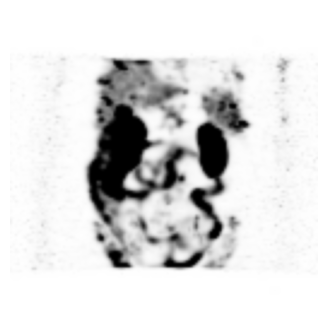

In [8]:
plt.figure(figsize=(4,4))
plt.imshow(maximum_intensity_projection.T, cmap='Greys', vmax=4, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.show()

Suppose we want to estimate the uncertainty in activity in one of the kidneys. Let's obtain it from an RTStruct file containing segmentations of all the organs. (The cell below is not required for this, but it will allow us to determine the mask names contained in the RTStruct file):

In [9]:
file_RT = os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'segmentations.dcm')
rtstruct = RTStructBuilder.create_from(
        dicom_series_path=path_CT, 
        rt_struct_path=file_RT
    )
print(rtstruct.get_roi_names())

['spleen', 'kidney_right', 'kidney_left', 'gallbladder', 'liver', 'stomach', 'pancreas', 'adrenal_gland_right', 'adrenal_gland_left', 'lung_upper_lobe_left', 'lung_lower_lobe_left', 'lung_upper_lobe_right', 'lung_middle_lobe_right', 'lung_lower_lobe_right', 'esophagus', 'trachea', 'thyroid_gland', 'small_bowel', 'duodenum', 'colon', 'urinary_bladder', 'sacrum', 'vertebrae_S1', 'vertebrae_L5', 'vertebrae_L4', 'vertebrae_L3', 'vertebrae_L2', 'vertebrae_L1', 'vertebrae_T12', 'vertebrae_T11', 'vertebrae_T10', 'vertebrae_T9', 'vertebrae_T8', 'vertebrae_T7', 'vertebrae_T6', 'vertebrae_T5', 'vertebrae_T4', 'vertebrae_T3', 'vertebrae_T2', 'vertebrae_T1', 'vertebrae_C7', 'vertebrae_C6', 'vertebrae_C5', 'vertebrae_C4', 'vertebrae_C3', 'vertebrae_C2', 'vertebrae_C1', 'heart', 'aorta', 'pulmonary_vein', 'brachiocephalic_trunk', 'subclavian_artery_right', 'subclavian_artery_left', 'common_carotid_artery_right', 'common_carotid_artery_left', 'brachiocephalic_vein_left', 'brachiocephalic_vein_right',

We can see the `'kidney_left'` is listed as one of the available masks. We can obtain this mask as follows:
* `io.load_mask` reads the RTStruct `file_RT`, and draws its ROIs on the CT they were drawn on, `reference` (the folder of the CT series); `rois` says which ROIs to draw
* `.on(object_meta, ...)` puts the mask on the reconstruction grid, by the place of both in the patient: `label` is the ROI, and `threshold=0.5` keeps the voxels it fills at least half of

In [10]:
mask_name = 'kidney_left'
kidney_mask = io.load_mask(file_RT, reference=path_CT, rois=[mask_name]).on(object_meta, label=mask_name, threshold=0.5)

We can compute the relative and absolute uncertainty corresponding to counts in this region using the `compute_uncertainty` function of the reconstruction algorithm. We also need to pass in the `DataStorageCallback` which contains every iterative update to the objects.

In [11]:
uncertainty_abs, uncertainty_pct = recon_algorithm.compute_uncertainty(
    mask = kidney_mask,
    data_storage_callback = data_storage_callback,
    return_pct = True,
    include_additive_term=True # must have additive_term_variance_estimate in likelihood
)
print(f'Estimated uncertainty in {mask_name}: {uncertainty_pct:.2f}%')

Estimated uncertainty in kidney_left: 0.95%


This can be repeated for any of the masks above! In addition, you can play around the with iterations, subsets (or even try different reconstruction algorithms) and see how it effects the estimated uncertainty.

## Multiple Bed Positions

PyTomography is also capable of uncertainty estimation in masks that are contained in two seperate bed positions. This uncertainty estimation takes into account the stitching weights between two different bed positions (if the mask is near the edge) when computing the organ variance in each seperate region.

* The code below is a summary of the multibed position tutorial, except that we now include a DataStorageCallback for each bed position

In [12]:
files_NM = [
    os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'bed1_projections.dcm'),
    os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'bed2_projections.dcm'),
]
path_CT = os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'CT')
files_CT = [os.path.join(path_CT, file) for file in os.listdir(path_CT)]

beds = io.SPECT.read_dicom_beds(files_NM)  # (projections, object_meta, proj_meta) of each bed, the inferior bed first


def initialize_reconstruction_algorithm_singlebed(projections, object_meta, proj_meta):
    # Change these depending on your file:
    index_peak = 1
    index_lower = 3
    index_upper = 2
    photopeak = projections[index_peak]
    scatter = io.SPECT.energy_window_scatter(projections, proj_meta, index_peak, index_lower, index_upper)
    # Build system matrix
    photon_energy = proj_meta.energy_windows[index_peak].photon_energy
    attenuation_map = io.attenuation_map(files_CT, object_meta, energy=photon_energy)
    psf_meta = io.SPECT.collimator_psf('GI-MEGP', photon_energy)
    att_transform = SPECTAttenuationTransform(attenuation_map)
    psf_transform = SPECTPSFTransform(psf_meta)
    # Create system matrix
    system_matrix = SPECTSystemMatrix(
        obj2obj_transforms = [att_transform,psf_transform],
        proj2proj_transforms= [],
        object_meta = object_meta,
        proj_meta = proj_meta)
    likelihood = PoissonLogLikelihood(system_matrix, photopeak, additive_term=scatter)
    reconstruction_algorithm = OSEM(likelihood)
    # Return only the reconstruction algorithm initialization (not calling it for any iterations/subsets yet)
    return reconstruction_algorithm

In order to compute uncertainty, we need to use the `PGAAMultiBedSPECT` reconstruction algorithm, which takes in multiple initialized reconstruction algorithms for each bed position (this class can also be used to reconstruct multiple bed positions without uncertainty as well). It places each bed by the `object_meta` of its system matrix, and stitches them with `io.SPECT.stitch_beds`.

In [13]:
recon_algo = PGAAMultiBedSPECT([initialize_reconstruction_algorithm_singlebed(*bed) for bed in beds])
# Initialize callback for each bed position
callbacks = [DataStorageCallback(r.likelihood, r.object_prediction) for r in recon_algo.reconstruction_algorithms]
print(recon_algo.estimate_memory(n_subsets=8))
reconstructed_image_multibed = recon_algo(4, 8, callback=callbacks)
object_meta_stitched = recon_algo.object_meta  # the grid of the stitched image

PGAAMultiBedSPECT (2 beds): 8 subsets
Peak ~ 4.7 GB RAM, 1.4 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.3 GB GPU (bed 1: what its reconstruction holds 0.2 GPU, bed 2: what its reconstruction holds 0.2 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU, the beds' images, stacked, and the stitched image 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.2 GB RAM, 0.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 0.2 RAM)
(plus whatever else your script keeps)


Lets plot the reconstruction (note how the liver overlaps two different bed positions, since it spans the center of the image)

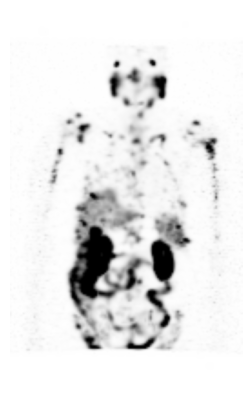

In [14]:
maximum_intensity_projection = reconstructed_image_multibed.max(axis=1)[0].cpu()
plt.figure(figsize=(3,5))
plt.imshow(maximum_intensity_projection.T, cmap='Greys', vmax=5, origin='lower', interpolation='gaussian')
plt.axis('off')
plt.show()

The organ mask goes on the grid of the stitched image: after the reconstruction, `recon_algo.object_meta` is that grid (the one `io.SPECT.stitch_beds` returns), which starts at the bottom slice of the lowest bed and runs through both. `.on()` puts the liver from the RTStruct onto it by the place of both in the patient, so the mask covers the liver in both beds.

In [15]:
mask_name = 'liver'
liver_mask = io.load_mask(file_RT, reference=path_CT, rois=[mask_name]).on(object_meta_stitched, label=mask_name, threshold=0.5)

Now we can compute the uncertainty in the liver, which spans both bed positions

In [16]:
uncertainty_abs, uncertainty_pct = recon_algo.compute_uncertainty(liver_mask, callbacks, return_pct=True)

In [17]:
print(f'Estimated uncertainty in {mask_name}: {uncertainty_pct:.2f}%')

Estimated uncertainty in liver: 0.51%


## Save the images

`io.save_dicom` writes both reconstructions as DICOM nuclear medicine (NM) files, with the patient and study of the projections (`reference=file_NM`), each in its place in the patient: bed 2's reconstruction on bed 2's grid (`object_meta`), and the stitched one on the stitched grid (`object_meta_stitched`).

In [18]:
for name, image, meta in [('osem_bed2', recon_OSEM, object_meta), ('osem_stitched', reconstructed_image_multibed, object_meta_stitched)]:
    io.save_dicom(image, OUTPUT / 't_uncertainty_spect' / name, meta, reference=file_NM,
                  series_description=name, overwrite=True)

In [19]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 0.71, "peak_ram_gb": 8.0}
